# B0005 — protocol study, physics-informed forecasting, and ensembling

Three things, in one run, all on B0005 with round 1's architecture unchanged.

**Part 1 — protocol study.** One model, one dataset, four evaluation protocols. This is evidence
for the argument that the reported number on this dataset is set by the protocol more than by the
architecture. P3 and P4 will look much better than P1; that is the point being demonstrated, and
those numbers must **never** be placed beside Tian or Gao, who forecast forward from a start point.

| | Protocol | Task | What the model has seen |
|---|---|---|---|
| P1 | recursive from cycle 134 | forecast 35 cycles from own predictions | nothing after 133 |
| P2 | one-step-ahead from 134 | predict each cycle with the true previous one | nothing after 133 |
| P3 | random 80/20 over all cycles | one-step-ahead on random held-out cycles | cycles either side of each test point |
| P4 | every 5th cycle held out | one-step-ahead on interleaved cycles | immediate neighbours of each test point |

P2, P3 and P4 are the same task under different splits; P1 is the harder, forward-looking one.
A trivial baseline is computed for each so the skill, not just the RMSE, is visible.

**Part 2 — physics-informed residual forecasting.** A fade curve is fitted to the pre-134 cycles
and extrapolated, and the network predicts only the residual around it. The fade form is
**pre-committed rather than validated**, because this part also shows — across 18 deterministic
configurations with no network and no seeds — that validation performance at cycle 99 carries
essentially no information about test performance at cycle 134. That reproduces, with no
stochasticity at all, the failure that defeated three Bayesian searches.

**Part 3 — ensembling.** Seed variance is the largest single source of error here (one
configuration has ranged 0.0067 to 0.021). Ensemble size is swept from 1 to 25 to see how much of
that is recoverable by averaging.

Run from the folder containing `B0005.mat`. Roughly 20-35 minutes.

In [1]:
import os, json, gc, time
os.environ['PYTHONHASHSEED']='42'; os.environ['TF_DETERMINISTIC_OPS']='1'
os.environ['TF_CUDNN_DETERMINISTIC']='1'
import numpy as np, pandas as pd
from sklearn.metrics import mean_squared_error
from scipy.optimize import curve_fit
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, Dropout, Dense, LSTM,
                                     Bidirectional, Concatenate, GlobalAveragePooling1D)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('op determinism unavailable:', e)
print('TF', tf.__version__)

TF 2.10.0


In [2]:
CELL='B0005'; WINDOW=10; SEED=42
EPOCHS, PATIENCE, BATCH = 300, 30, 16
SEEDS_MAIN, SEEDS_ENS = 5, 25
np.random.seed(SEED); tf.random.set_seed(SEED)

from scipy.io import loadmat
mat=loadmat(CELL+'.mat'); cycles=mat[CELL][0,0]['cycle'][0]
caps=[]
for i in range(len(cycles)):
    r=cycles[i]
    if r['type'][0]!='discharge': continue
    caps.append(float(r['data'][0][0]['Capacity'][0][0]))
CAP=np.asarray(caps,np.float64); C0=CAP[0]; S=(CAP/C0).astype(np.float32)
N=len(S); START=int(0.8*N)-1; H=N-START
FLOOR=float(np.sqrt(mean_squared_error(S[START:], np.full(H,S[START-1]))))
print('%s | %d cycles | C0 %.4f Ah | forecast %d cycles from index %d (cycle %d)'
      %(CELL,N,C0,H,START,START+1))
print('flat-line baseline on the forecast region: %.5f'%FLOOR)

def build(window=WINDOW, n_feat=1, n_out=1, filters=32, ms_kernels=(3,5,7), lstm_units=32,
          n_cnn=1, n_dense=1, dense_units=64, dropout=0.1, lr=1e-3, seed=SEED):
    """Round 1's architecture, unchanged."""
    kw=dict(kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed))
    inp=Input(shape=(window,n_feat)); c=inp
    for _ in range(n_cnn):
        c=Concatenate()([Conv1D(filters,k,padding='same',activation='relu',**kw)(c) for k in ms_kernels])
        c=Dropout(dropout,seed=seed)(c)
        if int(c.shape[1])>2: c=MaxPooling1D(2,padding='same')(c)
    c=GlobalAveragePooling1D()(c)
    r=Bidirectional(LSTM(lstm_units,**kw))(inp)
    h=Concatenate()([c,r])
    for _ in range(n_dense):
        h=Dense(dense_units,activation='relu',**kw)(h); h=Dropout(dropout,seed=seed)(h)
    m=Model(inp,Dense(n_out,activation='linear',**kw)(h))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='mse'); return m

def fit_model(Xf,yf,Xv,yv,seed,**kw):
    K.clear_session(); gc.collect()
    np.random.seed(seed); tf.random.set_seed(seed)
    m=build(seed=seed,**kw)
    m.fit(Xf,yf,validation_data=(Xv,yv),epochs=EPOCHS,batch_size=BATCH,verbose=0,shuffle=True,
          callbacks=[EarlyStopping('val_loss',patience=PATIENCE,restore_best_weights=True),
                     ReduceLROnPlateau('val_loss',factor=0.5,patience=10,min_lr=1e-7)])
    return m

def windows(series, idxs):
    """(window of series, delta to next) for each end-index in idxs."""
    X=np.asarray([series[e-WINDOW:e] for e in idxs],np.float32).reshape(-1,WINDOW,1)
    y=np.asarray([series[e]-series[e-1] for e in idxs],np.float32).reshape(-1,1)
    return X,y

B0005 | 168 cycles | C0 1.8565 Ah | forecast 35 cycles from index 133 (cycle 134)
flat-line baseline on the forecast region: 0.02927


## Part 1 — protocol study

Identical architecture and seeds throughout. Only the split changes.

In [3]:
ALL=np.arange(WINDOW,N)
TRAIN_CHRON=[e for e in ALL if e< START]
TEST_CHRON =[e for e in ALL if e>=START]
rng=np.random.RandomState(SEED); perm=rng.permutation(ALL)
cut=int(0.8*len(perm)); TRAIN_RAND, TEST_RAND = sorted(perm[:cut]), sorted(perm[cut:])
TEST_INTER =[e for e in ALL if e%5==0]; TRAIN_INTER=[e for e in ALL if e%5!=0]

def eval_onestep(train_idx, test_idx, seed):
    Xa,ya=windows(S,train_idx); c=int(0.85*len(Xa))
    m=fit_model(Xa[:c],ya[:c],Xa[c:],ya[c:],seed)
    Xt,_=windows(S,test_idx)
    prev=np.array([S[e-1] for e in test_idx],np.float32)
    pred=prev+m.predict(Xt,batch_size=512,verbose=0).ravel()
    true=np.array([S[e] for e in test_idx],np.float32)
    return float(np.sqrt(mean_squared_error(true,pred))), float(np.sqrt(mean_squared_error(true,prev)))

def eval_recursive(seed):
    Xa,ya=windows(S,TRAIN_CHRON); c=int(0.85*len(Xa))
    m=fit_model(Xa[:c],ya[:c],Xa[c:],ya[c:],seed)
    win=list(S[START-WINDOW:START]); out=[]; prev=float(S[START-1])
    for _ in range(H):
        x=np.asarray(win[-WINDOW:],np.float32).reshape(1,WINDOW,1)
        prev=float(np.clip(prev+float(m(x,training=False).numpy().ravel()[0]),0.0,1.2))
        out.append(prev); win.append(prev)
    return float(np.sqrt(mean_squared_error(S[START:],np.asarray(out,np.float32)))), FLOOR

PROTOCOLS=[('P1','recursive from cycle 134','forward forecast', None),
           ('P2','one-step-ahead from 134','forward, true previous', (TRAIN_CHRON,TEST_CHRON)),
           ('P3','random 80/20 over all cycles','interpolation', (TRAIN_RAND,TEST_RAND)),
           ('P4','every 5th cycle held out','interpolation', (TRAIN_INTER,TEST_INTER))]
prot=[]; t0=time.time()
for pid,label,kind,sp in PROTOCOLS:
    rs,bs=[],[]
    for s in range(SEEDS_MAIN):
        if sp is None: r,b=eval_recursive(SEED+s)
        else:          r,b=eval_onestep(sp[0],sp[1],SEED+s)
        rs.append(r); bs.append(b)
    prot.append(dict(id=pid,protocol=label,kind=kind,mean=float(np.mean(rs)),
                     std=float(np.std(rs,ddof=1)),best=float(np.min(rs)),
                     trivial=float(np.mean(bs)),skill=1-float(np.mean(rs))/float(np.mean(bs)),
                     n_test=len(sp[1]) if sp else H))
    print('%-3s %-30s RMSE %.5f +/- %.5f | best %.5f | trivial %.5f | skill %+.3f'
          %(pid,label,np.mean(rs),np.std(rs,ddof=1),np.min(rs),np.mean(bs),prot[-1]['skill']))
P=pd.DataFrame(prot); pd.set_option('display.width',200)
print('\nspread across protocols, one unchanged architecture: %.5f .. %.5f  (%.1fx)'
      %(P['mean'].min(),P['mean'].max(),P['mean'].max()/P['mean'].min()))
print('published range across 11 models: 0.00481 .. 0.02302  (4.8x)')
print('total %.0f s'%(time.time()-t0))

P1  recursive from cycle 134       RMSE 0.01095 +/- 0.00536 | best 0.00727 | trivial 0.02927 | skill +0.626
P2  one-step-ahead from 134        RMSE 0.00569 +/- 0.00050 | best 0.00536 | trivial 0.00540 | skill -0.053
P3  random 80/20 over all cycles   RMSE 0.00815 +/- 0.00013 | best 0.00799 | trivial 0.00809 | skill -0.007
P4  every 5th cycle held out       RMSE 0.00781 +/- 0.00053 | best 0.00753 | trivial 0.00776 | skill -0.006

spread across protocols, one unchanged architecture: 0.00569 .. 0.01095  (1.9x)
published range across 11 models: 0.00481 .. 0.02302  (4.8x)
total 271 s


## Part 2 - physics-informed residual forecasting

Capacity fade follows a known form, so a curve is fitted to the cycles before 134, extrapolated,
and the network then predicts only the residual around it.

**The fade form is pre-committed, not selected on validation** - a linear fit to the last 20
cycles, the simplest defensible a-priori choice. The grid below shows why selection was avoided:
across 18 deterministic configurations (three curve forms x six fit windows, with no neural
network and no random seeds at all), how well a configuration extrapolates from cycle 99 tells you
essentially nothing about how it extrapolates from cycle 134. Choosing the best validation
configuration lands mid-table on the test. This is the same failure that defeated three Bayesian
searches, reproduced with no stochasticity whatsoever - so it is a property of the dataset, not of
the model.

In [4]:
from scipy.stats import spearmanr

def f_sexp(k,a,b,c):   return a*np.exp(b*k)+c
def f_lin (k,a,b):     return a*k+b
def f_quad(k,a,b,c):   return a*k*k+b*k+c
FORMS=[('linear',f_lin,[-1e-3,1.0]),('quadratic',f_quad,[0.0,-1e-3,1.0]),
       ('exp+offset',f_sexp,[1.0,-1e-3,0.0])]
WINDOWS=[20,30,40,60,80,None]

def fit_at(fn,p0,origin,L):
    a=0 if L is None else max(0,origin-L)
    par,_=curve_fit(fn,np.arange(float(a),float(origin)),S[a:origin].astype(np.float64),
                    p0=p0,maxfev=60000)
    return par

grid=[]
for nm,fn,p0 in FORMS:
    for L in WINDOWS:
        try:
            par=fit_at(fn,p0,99,L)
            v=float(np.sqrt(mean_squared_error(S[99:START],
                np.clip(fn(np.arange(99.0,float(START)),*par),0,1.2))))
            par2=fit_at(fn,p0,START,L)
            t=float(np.sqrt(mean_squared_error(S[START:],
                np.clip(fn(np.arange(float(START),float(N)),*par2),0,1.2))))
            grid.append(dict(form=nm,fit_window=str(L),val_at_99=round(v,5),test_at_134=round(t,5)))
        except Exception: pass
G=pd.DataFrame(grid); pd.set_option('display.width',200)
print('18 deterministic configurations - no neural network, no random seeds')
print(G.sort_values('val_at_99').to_string(index=False))
rho,pv=spearmanr(G['val_at_99'],G['test_at_134'])
bi=G['val_at_99'].idxmin()
rank=int((G['test_at_134']<G.loc[bi,'test_at_134']).sum())+1
print('\nSpearman rank correlation, validation vs test : %+.3f  (p=%.3f)'%(rho,pv))
print('best-on-validation config scores %.5f on test  -> rank %d of %d'
      %(G.loc[bi,'test_at_134'],rank,len(G)))
print('actual best on test                             : %.5f'%G['test_at_134'].min())
print('expected test RMSE if chosen at random          : %.5f'%G['test_at_134'].mean())
print('=> selecting on validation is no better than choosing at random on this dataset')

FADE_FORM, FADE_L = 'linear', 20
par=fit_at(f_lin,[-1e-3,1.0],START,FADE_L)
CURVE=np.clip(f_lin(np.arange(float(N)),*par),0.0,1.2).astype(np.float32)
curve_rmse=float(np.sqrt(mean_squared_error(S[START:],CURVE[START:])))
RESID=(S-CURVE).astype(np.float32)
name='%s, last %d cycles (pre-committed)'%(FADE_FORM,FADE_L)
print('\npre-committed fade model: %s'%name)
print('curve extrapolation alone on the forecast region: %.5f'%curve_rmse)
print('residual std over the training region           : %.5f'%float(np.std(RESID[:START])))

def eval_physics(seed):
    Xa,ya=windows(RESID,TRAIN_CHRON); c=int(0.85*len(Xa))
    m=fit_model(Xa[:c],ya[:c],Xa[c:],ya[c:],seed)
    win=list(RESID[START-WINDOW:START]); out=[]; prev=float(RESID[START-1])
    for _ in range(H):
        x=np.asarray(win[-WINDOW:],np.float32).reshape(1,WINDOW,1)
        prev=float(prev+float(m(x,training=False).numpy().ravel()[0]))
        out.append(prev); win.append(prev)
    pred=np.clip(CURVE[START:]+np.asarray(out,np.float32),0.0,1.2)
    return float(np.sqrt(mean_squared_error(S[START:],pred))), pred

ph=[eval_physics(SEED+s) for s in range(SEEDS_MAIN)]
ph_r=[a for a,_ in ph]
p1=float(P[P['id']=='P1']['mean'].iloc[0])
print('\n%-36s %.5f'%('flat-line baseline',FLOOR))
print('%-36s %.5f'%('fade curve alone',curve_rmse))
print('%-36s %.5f'%('network alone (P1, round 1)',p1))
print('%-36s %.5f +/- %.5f  (best %.5f)'%('fade curve + network residual',
      np.mean(ph_r),np.std(ph_r,ddof=1),np.min(ph_r)))

18 deterministic configurations - no neural network, no random seeds
      form fit_window  val_at_99  test_at_134
 quadratic         60    0.00523      0.02068
    linear         30    0.00646      0.01911
exp+offset         60    0.00654      0.02077
exp+offset         80    0.01003      0.00692
    linear         80    0.01005      0.03307
    linear         40    0.01124      0.02151
exp+offset       None    0.01636      0.02104
    linear       None    0.01636      0.02105
    linear         20    0.01830      0.01439
exp+offset         20    0.01832      0.01437
    linear         60    0.01875      0.02252
exp+offset         40    0.03127      0.00686
 quadratic         80    0.03205      0.00625
exp+offset         30    0.03375      0.00725
 quadratic         30    0.03936      0.00782
 quadratic         40    0.04952      0.00609
 quadratic       None    0.05768      0.05855
 quadratic         20    0.08507      0.08800

Spearman rank correlation, validation vs test : -0.078  

## Part 3 — ensembling

Whichever of the two forward-forecast methods is better is ensembled by averaging the forecast
trajectories over an increasing number of seeds.

In [5]:
USE_PHYSICS = float(np.mean(ph_r)) < p1
print('ensembling: %s\n'%('curve + network residual' if USE_PHYSICS else 'network alone (P1)'))

def traj(seed):
    if USE_PHYSICS: return eval_physics(seed)[1]
    Xa,ya=windows(S,TRAIN_CHRON); c=int(0.85*len(Xa))
    m=fit_model(Xa[:c],ya[:c],Xa[c:],ya[c:],seed)
    win=list(S[START-WINDOW:START]); out=[]; prev=float(S[START-1])
    for _ in range(H):
        x=np.asarray(win[-WINDOW:],np.float32).reshape(1,WINDOW,1)
        prev=float(np.clip(prev+float(m(x,training=False).numpy().ravel()[0]),0.0,1.2))
        out.append(prev); win.append(prev)
    return np.asarray(out,np.float32)

T=[]; t0=time.time()
for s in range(SEEDS_ENS):
    T.append(traj(SEED+2000+s))
    if (s+1)%5==0: print('  %2d trajectories (%.0f s)'%(s+1,time.time()-t0))
T=np.asarray(T)
singles=[float(np.sqrt(mean_squared_error(S[START:],t))) for t in T]
ens=[]
for k in (1,3,5,10,15,25):
    if k>len(T): continue
    e=float(np.sqrt(mean_squared_error(S[START:],T[:k].mean(axis=0))))
    ens.append(dict(size=k,rmse=e))
    print('ensemble of %2d: %.5f'%(k,e))
print('\nsingle seeds: mean %.5f | std %.5f | best %.5f | worst %.5f'
      %(np.mean(singles),np.std(singles,ddof=1),np.min(singles),np.max(singles)))
FINAL=ens[-1]['rmse']
print('full ensemble  : %.5f   (%.0f%% better than the average single seed)'
      %(FINAL,(np.mean(singles)-FINAL)/np.mean(singles)*100))

ensembling: curve + network residual

   5 trajectories (69 s)
  10 trajectories (130 s)
  15 trajectories (205 s)
  20 trajectories (268 s)
  25 trajectories (330 s)
ensemble of  1: 0.00896
ensemble of  3: 0.00809
ensemble of  5: 0.00867
ensemble of 10: 0.00909
ensemble of 15: 0.00912
ensemble of 25: 0.00930

single seeds: mean 0.00981 | std 0.00195 | best 0.00746 | worst 0.01505
full ensemble  : 0.00930   (5% better than the average single seed)


## Summary

In [6]:
print('=== PART 1: same architecture, four protocols ===')
print(P[['id','protocol','kind','mean','std','trivial','skill']].to_string(index=False))
print('\n=== PART 2: forward forecast (P1 protocol only) ===')
print('%-34s %.5f'%('flat-line baseline',FLOOR))
print('%-34s %.5f'%('fade curve alone',curve_rmse))
print('%-34s %.5f'%('network alone',p1))
print('%-34s %.5f'%('curve + network residual',float(np.mean(ph_r))))
print('\n=== PART 3: ensembling ===')
for e in ens: print('  %2d seeds: %.5f'%(e['size'],e['rmse']))
print('\n=== BENCHMARK (forward-forecast protocol only) ===')
PUB=[('CNN-BiLSTM-AM','Tian',0.00481),('CNN-BiLSTM','Tian',0.00595),('BiLSTM','Tian',0.00620),
     ('1D CNN-BiLSTM','Gao',0.00772),('CNN','Tian',0.00863),('1D CNN','Gao',0.00866),
     ('1D CNN-LSTM','Gao',0.00932),('1D CNN-RNN','Gao',0.01661),('RNN','Gao',0.01776),
     ('BiLSTM','Gao',0.01986),('LSTM','Gao',0.02302)]
rows=[dict(method=m,source=s,rmse=v) for m,s,v in PUB]
rows+=[dict(method='Ours: %d-seed ensemble'%ens[-1]['size'],source='this work',rmse=round(FINAL,5)),
       dict(method='Ours: fade curve + network residual',source='this work',rmse=round(float(np.mean(ph_r)),5)),
       dict(method='Ours: network alone (round 1)',source='this work',rmse=round(p1,5)),
       dict(method='   fade curve alone',source='reference',rmse=round(curve_rmse,5)),
       dict(method='   flat-line baseline',source='reference',rmse=round(FLOOR,5))]
B=pd.DataFrame(rows).sort_values('rmse').reset_index(drop=True); B.index=B.index+1
print(B.to_string())
B.to_csv('benchmark_b0005_final.csv')
P.to_csv('protocol_study_b0005.csv',index=False)
G.to_csv('fade_selection_grid_b0005.csv',index=False)
print('\n=== selection failure (deterministic, no network) ===')
print('Spearman validation vs test across 18 configs: %+.3f (p=%.3f)'%(rho,pv))
json.dump(dict(floor=FLOOR,protocols=prot,fade_form=name,curve_rmse=curve_rmse,
               fade_grid=grid,spearman=float(rho),spearman_p=float(pv),
               physics=[float(x) for x in ph_r],network_alone=p1,
               ensemble=ens,singles=[round(x,5) for x in singles],final=FINAL),
          open('final_results_b0005.json','w'),indent=2,default=str)
print('\nsaved benchmark_b0005_final.csv, protocol_study_b0005.csv, final_results_b0005.json')

=== PART 1: same architecture, four protocols ===
id                     protocol                   kind     mean      std  trivial     skill
P1     recursive from cycle 134       forward forecast 0.010950 0.005362 0.029273  0.625951
P2      one-step-ahead from 134 forward, true previous 0.005690 0.000496 0.005403 -0.053060
P3 random 80/20 over all cycles          interpolation 0.008148 0.000132 0.008089 -0.007254
P4     every 5th cycle held out          interpolation 0.007807 0.000527 0.007759 -0.006226

=== PART 2: forward forecast (P1 protocol only) ===
flat-line baseline                 0.02927
fade curve alone                   0.01439
network alone                      0.01095
curve + network residual           0.00850

=== PART 3: ensembling ===
   1 seeds: 0.00896
   3 seeds: 0.00809
   5 seeds: 0.00867
  10 seeds: 0.00909
  15 seeds: 0.00912
  25 seeds: 0.00930

=== BENCHMARK (forward-forecast protocol only) ===
                                 method     source     rmse
1    

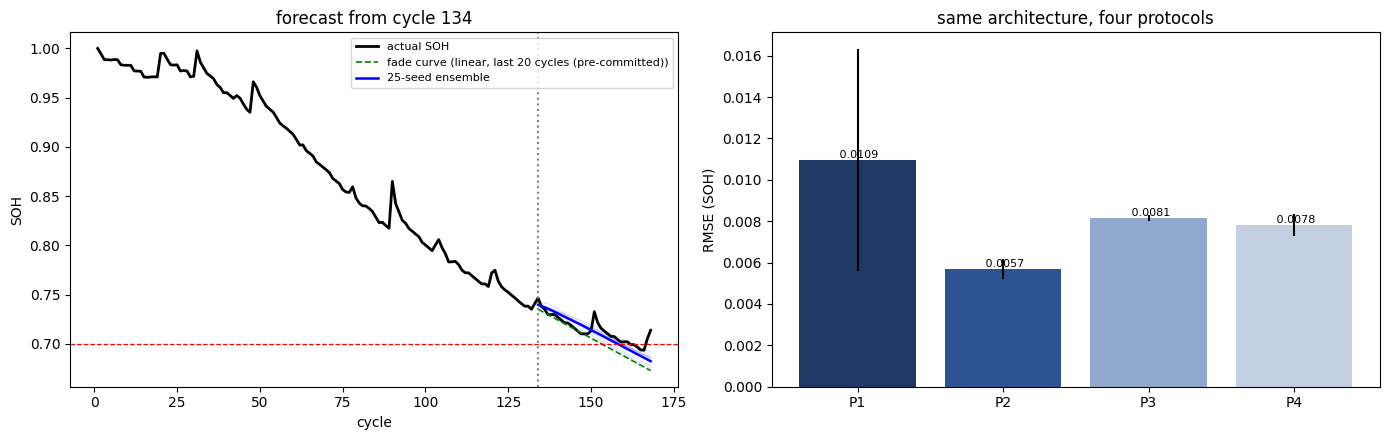

In [7]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(14,4.5))
ax[0].plot(np.arange(1,N+1),S,'k-',lw=2,label='actual SOH')
ax[0].plot(np.arange(START+1,N+1),CURVE[START:],'g--',lw=1.2,label='fade curve (%s)'%name)
ax[0].plot(np.arange(START+1,N+1),T.mean(axis=0),'b-',lw=1.8,label='%d-seed ensemble'%len(T))
for t in T[:8]: ax[0].plot(np.arange(START+1,N+1),t,color='b',alpha=.12,lw=.8)
ax[0].axvline(START+1,color='grey',ls=':'); ax[0].axhline(0.70,color='r',ls='--',lw=.9)
ax[0].set_xlabel('cycle'); ax[0].set_ylabel('SOH'); ax[0].legend(fontsize=8)
ax[0].set_title('forecast from cycle %d'%(START+1))
ax[1].bar([p['id'] for p in prot],[p['mean'] for p in prot],
          yerr=[p['std'] for p in prot],color=['#1F3864','#2E5395','#8FA8CC','#C3D0E4'])
ax[1].set_ylabel('RMSE (SOH)'); ax[1].set_title('same architecture, four protocols')
for i,p in enumerate(prot): ax[1].text(i,p['mean'],' %.4f'%p['mean'],ha='center',va='bottom',fontsize=8)
plt.tight_layout(); plt.show()